In [1]:
# Install required packages
!pip install pandas numpy matplotlib seaborn scikit-learn nltk


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from imblearn.over_sampling import SMOTE
import re
import warnings
warnings.filterwarnings('ignore')

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Set the file path
file_path = '/content/drive/MyDrive/Dataset.csv'

# Load the dataset into a DataFrame
df = pd.read_csv(file_path)

# Drop the 'Unnamed: 0' column if it exists (often created when saving from Excel/CSV)
if 'Unnamed: 0' in df.columns:
    df.drop('Unnamed: 0', axis=1, inplace=True)

# Display the first 5 rows
df.head()

,text,Emotion
0,i seriously hate one subject to death but now ...,hate
1,im so full of life i feel appalled,neutral
2,i sit here to write i start to dig out my feel...,neutral
3,ive been really angry with r and i feel like a...,anger
4,i feel suspicious if there is no one outside l...,neutral


In [5]:
# Check the shape of the dataset (rows, columns)
df.shape


(839555, 2)

In [6]:
# Remove duplicate rows
num_duplicates = df.duplicated().sum()
print("Number of duplicate rows:", num_duplicates)
df = df.drop_duplicates()
print("After removing duplicates, dataset shape:", df.shape)

Number of duplicate rows: 445733
After removing duplicates, dataset shape: (393822, 2)


In [7]:
# See how many missing values are in each column
df.isnull().sum()

,0
text,0
Emotion,0


In [8]:
df.shape

(393822, 2)

In [9]:
# Look at how many samples we have for each emotion
df['Emotion'].value_counts()

,count
Emotion,
neutral,316935
love,17634
happiness,13038
sadness,8485
relief,8007
hate,6160
anger,5952
fun,4854
enthusiasm,4497


In [10]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english')) - {"not", "no", "never"}

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text, re.I|re.A)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess_text)

label_encoder = LabelEncoder()
df['encoded_emotion'] = label_encoder.fit_transform(df['Emotion'])


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Split data into train/test
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['encoded_emotion'],
    test_size=0.3,
    random_state=42,
    stratify=df['encoded_emotion']
)

# TF-IDF with N-grams
vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 3),      # unigrams + bigrams + trigrams
    sublinear_tf=True,       # log-scaled term frequency
    min_df=3,               # ignore rare terms
    max_df=0.9               # ignore overly common terms
)

# Fit TF-IDF on training data and transform test data
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Dataset distribution check (NO SMOTE)
print("Training label distribution:", np.bincount(y_train))
print("TF-IDF feature matrix shape:", X_train_tfidf.shape)


Training label distribution: [  4166     43   1888   3148   3398   9127   4312  12344 221854   5605
   5939   2401   1450]
TF-IDF feature matrix shape: (275675, 15000)


In [12]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression with class balancing
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    n_jobs=-1
)

# Train model
log_reg.fit(X_train_tfidf, y_train)

# Predictions
y_pred_lr = log_reg.predict(X_test_tfidf)

# Evaluation
print("=== Logistic Regression Report ===")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=label_encoder.classes_
))


=== Logistic Regression Report ===
              precision    recall  f1-score   support

       anger       0.97      0.97      0.97      1786
     boredom       0.67      0.78      0.72        18
       empty       0.97      0.95      0.96       809
  enthusiasm       1.00      0.97      0.98      1349
         fun       0.95      0.94      0.94      1456
   happiness       0.99      0.99      0.99      3911
        hate       0.99      0.98      0.98      1848
        love       0.99      0.98      0.99      5290
     neutral       1.00      1.00      1.00     95081
      relief       0.98      0.97      0.97      2402
     sadness       1.00      0.97      0.98      2546
    surprise       0.99      0.97      0.98      1029
       worry       0.92      0.97      0.94       622

    accuracy                           0.99    118147
   macro avg       0.95      0.96      0.95    118147
weighted avg       0.99      0.99      0.99    118147



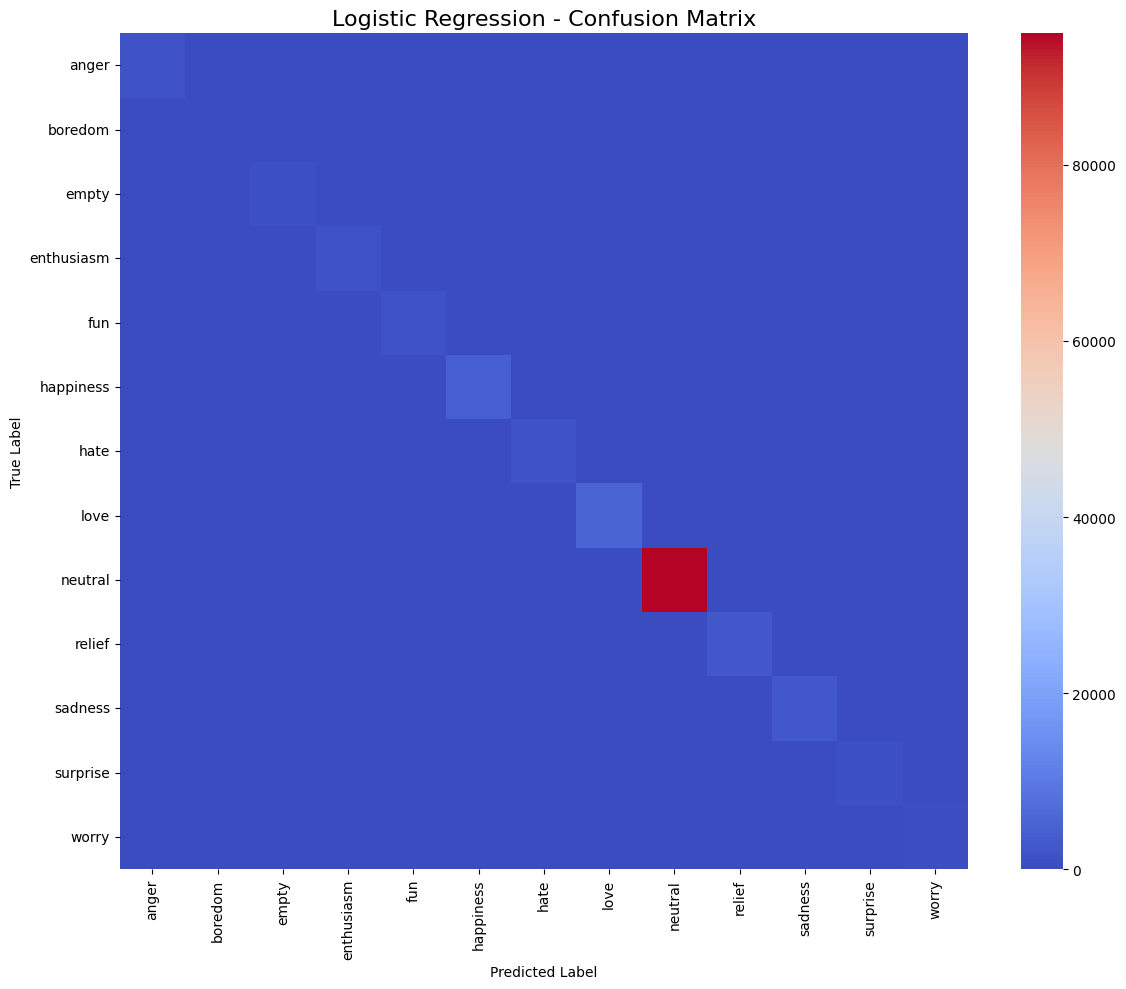

Accuracy: 0.9933049506123727
F1 Score (Weighted): 0.9932907606200423
Precision (Weighted): 0.9933177583609222
Recall (Weighted): 0.9933049506123727


In [13]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

# Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_lr,
    annot=False,
    cmap="coolwarm",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Logistic Regression - Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Evaluation Metrics
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("F1 Score (Weighted):", f1_score(y_test, y_pred_lr, average="weighted"))
print("Precision (Weighted):", precision_score(y_test, y_pred_lr, average="weighted"))
print("Recall (Weighted):", recall_score(y_test, y_pred_lr, average="weighted"))


In [14]:
from sklearn.svm import LinearSVC

# Support Vector Machine with class balancing
svm_model = LinearSVC(
    max_iter=3000,
    class_weight="balanced"
)

# Train model
svm_model.fit(X_train_tfidf, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test_tfidf)

# Evaluation
print("=== Support Vector Machine Report ===")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=label_encoder.classes_
))


=== Support Vector Machine Report ===
              precision    recall  f1-score   support

       anger       0.99      0.97      0.98      1786
     boredom       0.93      0.72      0.81        18
       empty       1.00      0.95      0.97       809
  enthusiasm       1.00      0.98      0.99      1349
         fun       0.98      0.94      0.96      1456
   happiness       0.99      0.99      0.99      3911
        hate       0.99      0.98      0.99      1848
        love       1.00      0.99      0.99      5290
     neutral       1.00      1.00      1.00     95081
      relief       0.99      0.97      0.98      2402
     sadness       1.00      0.97      0.99      2546
    surprise       1.00      0.97      0.98      1029
       worry       0.92      0.97      0.95       622

    accuracy                           0.99    118147
   macro avg       0.98      0.95      0.97    118147
weighted avg       0.99      0.99      0.99    118147



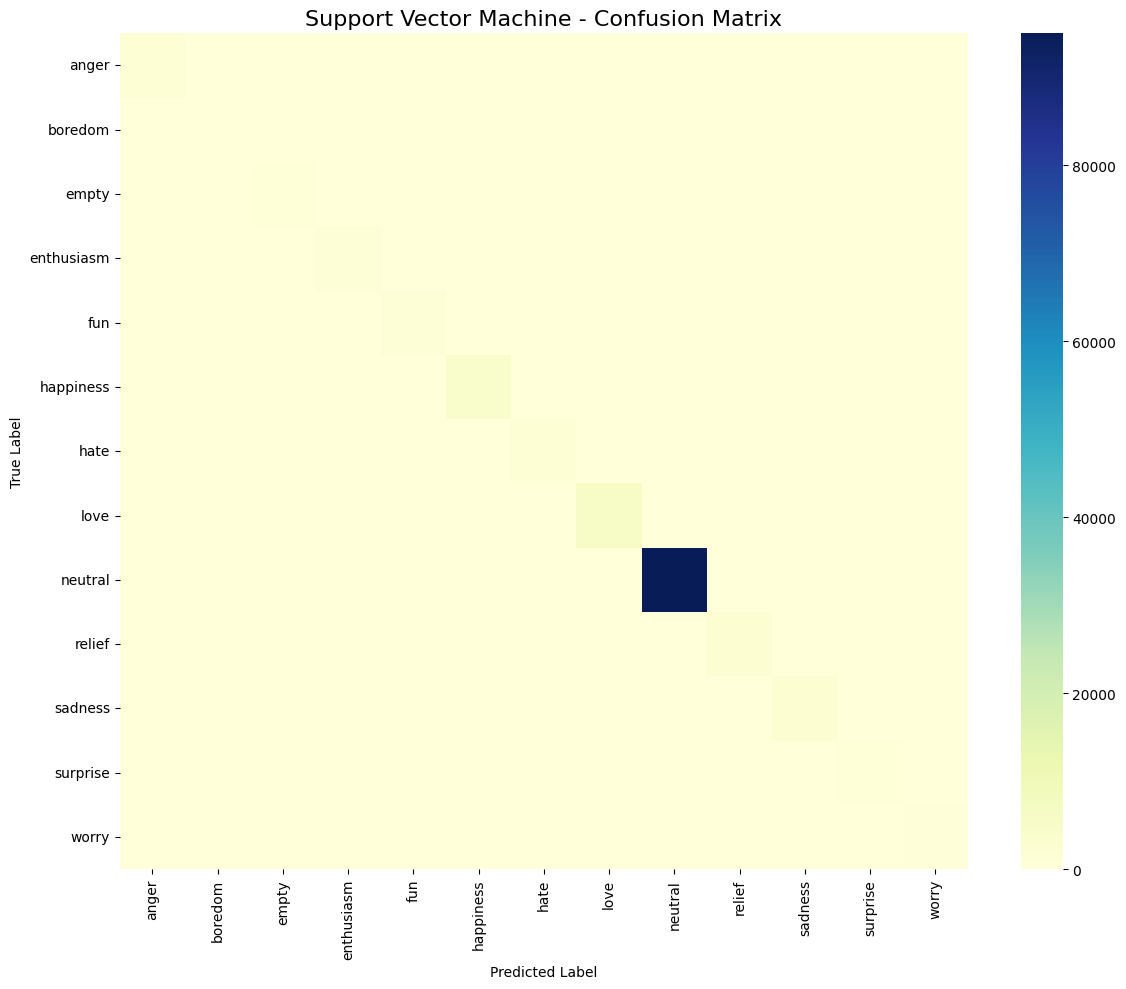

Accuracy: 0.9948030842932957
F1 Score (Weighted): 0.9947778999479254
Precision (Weighted): 0.994809708353781
Recall (Weighted): 0.9948030842932957


In [15]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

# Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_svm,
    annot=False,
    cmap="YlGnBu",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Support Vector Machine - Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Evaluation Metrics
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("F1 Score (Weighted):", f1_score(y_test, y_pred_svm, average="weighted"))
print("Precision (Weighted):", precision_score(y_test, y_pred_svm, average="weighted"))
print("Recall (Weighted):", recall_score(y_test, y_pred_svm, average="weighted"))


In [17]:
import joblib

joblib.dump(log_reg, "logistic_regression_model.pkl")
joblib.dump(svm_model, "svm_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Models, vectorizer, and encoder saved successfully!")


Models, vectorizer, and encoder saved successfully!
